# Mantis на PAMAP2: замороженный кодировщик, слои, токены, масштабы, классификаторы

Ноутбук **только определяет код** — все эксперименты запускаются вручную сверху вниз.
Mantis **не реализуется заново**: используется готовый предобученный кодировщик с Hugging Face (`paris-noah/Mantis-8M`, пакет `mantis-tsfm`).

## Что устроено в Mantis (кратко, по статье и README)
* Вход — временной ряд одного канала длиной, кратной 32; по умолчанию ряд интерполируется до **512**. Мультиканальные данные обрабатываются **канал за каналом**, эмбеддинги каналов конкатенируются (`C × q`).
* **Token Generator Unit**: instance-норма → три ветки (свёртка + mean-pooling по сигналу, то же по первой разности, кодирование среднего/СКО по патчам) → конкатенация → linear + LayerNorm → **ровно 32 токена** (dim 256).
* **Transformer**: prepended CLS-токен, RoPE, 6 слоёв (8 голов), RMSNorm, SwiGLU, pre-norm.
* Предобучение: contrastive InfoNCE (Random Crop Resize) на синтетике CauKer.
* Zero-shot: берём **промежуточный слой** (`return_transf_layer`, нумерация с 0) и агрегацию токенов (`output_token`: `cls_token` / `mean_token` / `combined` = CLS ‖ mean).


In [ ]:
%pip install -q mantis-tsfm scikit-learn pandas matplotlib requests tqdm lightgbm huggingface_hub

## 1. Вычислительная конфигурация

In [ ]:
import os, re, sys, time, json, random, zipfile, warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Optional, Tuple

import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from tqdm.auto import tqdm
from pathlib import Path
from huggingface_hub import hf_hub_download

warnings.filterwarnings("ignore")


@dataclass
class Config:
    seed: int = 42
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    workdir: Path = Path("./work_pamap2")

    # --- данные ---
    downsample: int = 3                 # 100 Гц -> ~33 Гц (усреднение по 3 отсчётам)
    window: int = 128                   # ~3.9 с
    step: int = 64                      # 50% перекрытие
    channels_mode: str = "acc_gyro"     # 'acc' (9 кан.) | 'acc_gyro' (18) | 'acc_gyro_mag' (27)
    train_subjects: Tuple[int, ...] = (101, 102, 103, 107, 108, 109)
    val_subjects: Tuple[int, ...] = (104,)
    test_subjects: Tuple[int, ...] = (105, 106)

    # --- Mantis ---
    model_name: str = "Mantis-8M"       # 'Mantis-8M' | 'MantisPlus' | 'MantisV2'
    n_layers: int = 6                   # число transformer-слоёв (индексы 0..n_layers-1)
    mantis_len: int = 512               # длина, к которой интерполируем ряд
    extract_chunk: int = 1000           # окон за один вызов transform
    extract_batch: int = 512            # batch_size внутри transform (если поддерживается)

    # --- базовый трансформер ---
    bl_epochs: int = 40
    bl_batch: int = 128
    bl_lr: float = 1e-3

    # --- эксперименты ---
    grid_train_cap: Optional[int] = None    # ограничить число train-окон в слой×токен сетке (ускорение)
    scales: Tuple[int, ...] = (128, 256, 512, 1024)   # масштабы (длины интерполяции), кратные 32
    pca_dim_for_trees: int = 128            # PCA перед RF/бустингами
    # эпохи дообучения
    ft_train_cap: int = 4000
    ft_batch: int = 32
    ft_lr: float = 2e-4
    ft_weight_decay: float = 0.05
    ft_checkpoints: Tuple[int, ...] = (0, 1, 2, 5, 10, 20, 30)
    ft_probe_train_cap: int = 3000
    ft_probe_token: str = "combined"
    # кривая обучения
    lc_fractions: Tuple[float, ...] = (0.02, 0.05, 0.1, 0.25, 1.0)


cfg = Config()
cfg.workdir.mkdir(parents=True, exist_ok=True)
if cfg.device == "cpu":
    cfg.extract_batch, cfg.extract_chunk = 128, 300
    print("ВНИМАНИЕ: GPU не найден, всё будет работать на CPU (медленно). "
          "Рекомендуется уменьшить channels_mode, ft_train_cap, grid_train_cap.")

def set_seed(seed=cfg.seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

print("device:", cfg.device)
if cfg.device == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}, память: {p.total_memory/1e9:.1f} ГБ")
print("torch:", torch.__version__, "| CPU ядер:", os.cpu_count())
print(cfg)

device: cuda
GPU: Tesla T4, память: 15.6 ГБ
torch: 2.11.0+cu130 | CPU ядер: 2
Config(seed=42, device='cuda', workdir=PosixPath('work_pamap2'), downsample=3, window=128, step=64, channels_mode='acc_gyro', train_subjects=(101, 102, 103, 107, 108, 109), val_subjects=(104,), test_subjects=(105, 106), model_name='Mantis-8M', n_layers=6, mantis_len=512, extract_chunk=1000, extract_batch=512, bl_epochs=40, bl_batch=128, bl_lr=0.001, grid_train_cap=None, scales=(128, 256, 512, 1024), pca_dim_for_trees=128, ft_train_cap=4000, ft_batch=32, ft_lr=0.0002, ft_weight_decay=0.05, ft_checkpoints=(0, 1, 2, 5, 10, 20, 30), ft_probe_train_cap=3000, ft_probe_token='combined', lc_fractions=(0.02, 0.05, 0.1, 0.25, 1.0))


## 2. Датасет PAMAP2 (Human Activity Recognition)
3 IMU (кисть, грудь, лодыжка), 100 Гц, 12 протокольных активностей. Используем акселерометр ±16g и гироскоп (опционально магнитометр); heart rate, температуру, orientation и второй акселерометр отбрасываем.
Разбиение **по испытуемым** (subject-wise), чтобы не было утечки между перекрывающимися окнами: train / val (выбор слоя и гиперпараметров) / test (итоговые цифры).

PAMAP2_Dataset/Protocol/subject101.dat: reconstructing file:   0%|          |  0.00B /  142MB            

PAMAP2_Dataset/Protocol/subject101.dat: downloading bytes:           |  0.00B            

Загружен: subject101.dat


PAMAP2_Dataset/Protocol/subject102.dat: reconstructing file:   0%|          |  0.00B /  207MB            

PAMAP2_Dataset/Protocol/subject102.dat: downloading bytes:           |  0.00B            

...

subject109.dat:   0%|          | 0.00/3.89M [00:00<?, ?B/s]

Загружен: subject109.dat


subjects:   0%|          | 0/9 [00:00<?, ?it/s]

испытуемые: [101, 102, 103, 104, 105, 106, 107, 108, 109] | каналов: 18
{'train': (6058, 18, 128), 'val': (1181, 18, 128), 'test': (2666, 18, 128)}


,train,val,test
lying,627,118,241
sitting,563,131,256
standing,608,127,238
walking,765,164,296
running,256,0,242
cycling,498,116,231
nordic walking,553,142,272
ascending stairs,359,83,137
descending stairs,325,70,118
vacuum cleaning,563,102,233


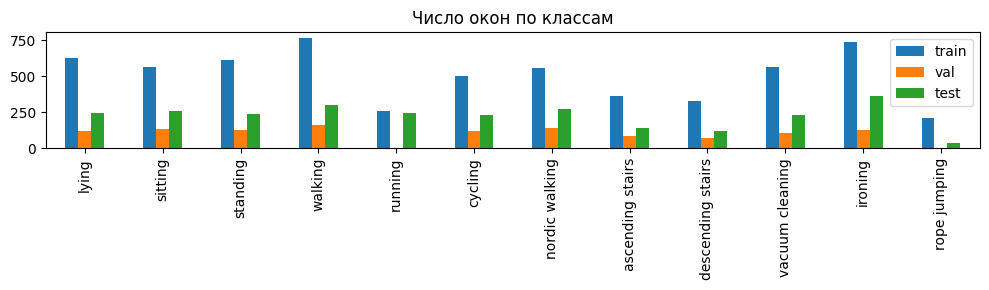

In [ ]:
PAMAP_URL = "https://archive.ics.uci.edu/static/public/231/pamap2+physical+activity+monitoring.zip"
ACT_IDS = [1, 2, 3, 4, 5, 6, 7, 12, 13, 16, 17, 24]
ACT_NAMES = ["lying", "sitting", "standing", "walking", "running", "cycling", "nordic walking",
             "ascending stairs", "descending stairs", "vacuum cleaning", "ironing", "rope jumping"]
ACT_MAP = {a: i for i, a in enumerate(ACT_IDS)}
N_CLASSES = len(ACT_IDS)
IMU_BASES = {"hand": 3, "chest": 20, "ankle": 37}   # смещение столбцов блока IMU в .dat файле

REPO_ID = "yonful/gem-analysis-pamap2"

def ensure_pamap2():
    raw = cfg.workdir / "raw"
    protocol_dir = raw / "PAMAP2_Dataset" / "Protocol"
    protocol_dir.mkdir(parents=True, exist_ok=True)

    # Скачиваем записи всех 9 испытуемых
    for sid in range(101, 110):
        filename = f"PAMAP2_Dataset/Protocol/subject{sid}.dat"

        path = hf_hub_download(
            repo_id=REPO_ID,
            repo_type="dataset",
            filename=filename,
            local_dir=raw,
        )

        print(f"Загружен: subject{sid}.dat")

    files = sorted(protocol_dir.glob("subject*.dat"))

    if not files:
        raise FileNotFoundError(
            f"Не найдены файлы Protocol в {protocol_dir}"
        )

    return files


def channel_columns():
    use = {"acc": ["acc"], "acc_gyro": ["acc", "gyro"], "acc_gyro_mag": ["acc", "gyro", "mag"]}[cfg.channels_mode]
    cols, names = [], []
    for imu, b in IMU_BASES.items():
        groups = {"acc": [b + 1, b + 2, b + 3], "gyro": [b + 7, b + 8, b + 9], "mag": [b + 10, b + 11, b + 12]}
        for g in use:
            for ax, c in zip("xyz", groups[g]):
                cols.append(c); names.append(f"{imu}_{g}_{ax}")
    return cols, names


def load_subject(path, cols):
    df = pd.read_csv(path, sep=r"\s+", header=None)
    sid = int(re.search(r"subject(\d+)", path.name).group(1))
    lab = df[1].to_numpy().astype(int)
    sens = df[cols].interpolate(limit_direction="both").to_numpy(np.float32)    # заполняем выпадения сенсоров
    lab = np.array([ACT_MAP.get(a, -1) for a in lab])                            # -1 = переходные/неиспользуемые
    d = cfg.downsample
    T = len(sens) // d * d
    sens = sens[:T].reshape(-1, d, sens.shape[1]).mean(1)
    lab = lab[:T].reshape(-1, d)[:, d // 2]
    W, S = cfg.window, cfg.step
    xs = sliding_window_view(sens, W, axis=0)[::S]          # (n, C, W)
    ls = sliding_window_view(lab, W)[::S]                   # (n, W)
    ok = (ls.min(1) == ls.max(1)) & (ls[:, 0] >= 0)         # только «чистые» окна одной активности
    return sid, np.ascontiguousarray(xs[ok]), ls[ok, 0].astype(np.int64)


files = ensure_pamap2()
cols, ch_names = channel_columns()
per_subject = {}
for f in tqdm(files, desc="subjects"):
    sid, X, y = load_subject(f, cols)
    per_subject[sid] = (X, y)
print("испытуемые:", sorted(per_subject), "| каналов:", len(cols))


def gather(subjects):
    Xs = [per_subject[s][0] for s in subjects if s in per_subject]
    ys = [per_subject[s][1] for s in subjects if s in per_subject]
    return np.concatenate(Xs), np.concatenate(ys)

X_train, y_train = gather(cfg.train_subjects)
X_val, y_val = gather(cfg.val_subjects)
X_test, y_test = gather(cfg.test_subjects)

# стандартизация по статистике train (по каналам)
mu = X_train.mean(axis=(0, 2), keepdims=True)
sd = X_train.std(axis=(0, 2), keepdims=True) + 1e-6
X_train, X_val, X_test = [((a - mu) / sd).astype(np.float32) for a in (X_train, X_val, X_test)]

SPLITS_X = {"train": X_train, "val": X_val, "test": X_test}
SPLITS_Y = {"train": y_train, "val": y_val, "test": y_test}
N_CH = X_train.shape[1]
print({k: v.shape for k, v in SPLITS_X.items()})

cnt = pd.DataFrame({k: np.bincount(v, minlength=N_CLASSES) for k, v in SPLITS_Y.items()}, index=ACT_NAMES)
display(cnt)
cnt.plot.bar(figsize=(10, 3), title="Число окон по классам"); plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

RESULTS = []   # сюда складываем все итоговые результаты для финальной таблицы

def add_result(name, val_acc, test_acc, test_f1, **extra):
    RESULTS.append(dict(model=name, val_acc=val_acc, test_acc=test_acc, test_f1=test_f1, **extra))

def metrics(y_true, y_pred):
    return accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average="macro")

## 3. Базовая модель: простой трансформер, обученный с нуля
Патч-эмбеддинг (Conv1d) → CLS-токен + обучаемые позиции → 3 слоя `TransformerEncoder` → linear. Вход — окна в исходном разрешении (`window` отсчётов, без интерполяции). Лучшая эпоха выбирается по val.

epoch   1 | loss 1.8938 | val acc 0.5758
epoch   5 | loss 0.5121 | val acc 0.8417
epoch  10 | loss 0.3901 | val acc 0.7705
epoch  15 | loss 0.3593 | val acc 0.8628
epoch  20 | loss 0.3290 | val acc 0.8391
epoch  25 | loss 0.3123 | val acc 0.8789
epoch  30 | loss 0.3028 | val acc 0.8704
epoch  35 | loss 0.3006 | val acc 0.8662
epoch  40 | loss 0.3002 | val acc 0.8662

Baseline Transformer: val acc 0.8916 | test acc 0.8593 | test F1 0.8602 | 29 c


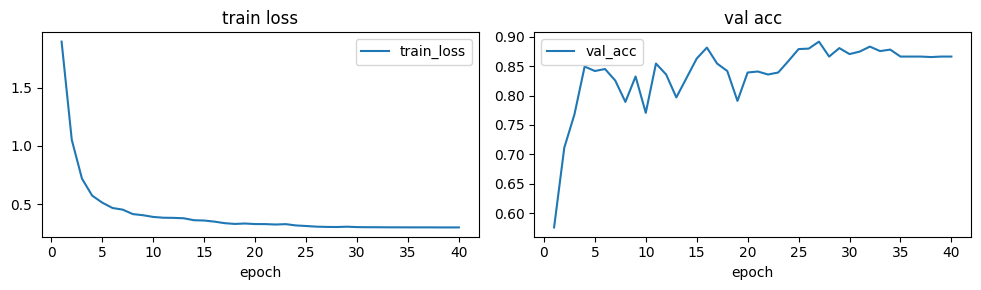

In [ ]:
class SimpleTSTransformer(nn.Module):
    def __init__(self, in_ch, seq_len, n_classes, d_model=128, n_heads=4, n_layers=3, patch=8, dropout=0.1):
        super().__init__()
        assert seq_len % patch == 0
        self.patch_embed = nn.Conv1d(in_ch, d_model, kernel_size=patch, stride=patch)
        n_tok = seq_len // patch
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos = nn.Parameter(torch.zeros(1, n_tok + 1, d_model))
        nn.init.trunc_normal_(self.cls, std=0.02); nn.init.trunc_normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, dim_feedforward=4 * d_model, dropout=dropout,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, n_classes)

    def forward(self, x):                       # x: (B, C, L)
        t = self.patch_embed(x).transpose(1, 2)
        t = torch.cat([self.cls.expand(len(t), -1, -1), t], 1) + self.pos
        return self.head(self.norm(self.encoder(t)[:, 0]))


@torch.no_grad()
def predict_torch(model, X, bs=512):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(cfg.device)
        out.append(model(xb).argmax(1).cpu().numpy())
    return np.concatenate(out)


def train_baseline(Xtr, ytr, Xva, yva, Xte, yte, epochs=cfg.bl_epochs, seed=cfg.seed, verbose=True):
    set_seed(seed)
    model = SimpleTSTransformer(Xtr.shape[1], Xtr.shape[2], N_CLASSES).to(cfg.device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.bl_lr, weight_decay=1e-2)
    steps = epochs * int(np.ceil(len(Xtr) / cfg.bl_batch))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg.bl_lr, total_steps=steps)
    Xt, yt = torch.from_numpy(Xtr), torch.from_numpy(ytr)
    best, best_state, hist = -1, None, []
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xt))
        tot = 0.0
        for i in range(0, len(perm), cfg.bl_batch):
            idx = perm[i:i + cfg.bl_batch]
            xb = Xt[idx].to(cfg.device); yb = yt[idx].to(cfg.device)
            xb = xb + 0.02 * torch.randn_like(xb)                        # лёгкая аугментация шумом
            loss = F.cross_entropy(model(xb), yb, label_smoothing=0.05)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tot += loss.item() * len(idx)
        va = accuracy_score(yva, predict_torch(model, Xva))
        hist.append((ep, tot / len(Xt), va))
        if va > best:
            best = va; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"epoch {ep:3d} | loss {tot/len(Xt):.4f} | val acc {va:.4f}")
    model.load_state_dict(best_state)
    te_acc, te_f1 = metrics(yte, predict_torch(model, Xte))
    return dict(val_acc=best, test_acc=te_acc, test_f1=te_f1, history=hist)


t0 = time.time()
bl = train_baseline(X_train, y_train, X_val, y_val, X_test, y_test)
print(f"\nBaseline Transformer: val acc {bl['val_acc']:.4f} | test acc {bl['test_acc']:.4f} | test F1 {bl['test_f1']:.4f} "
      f"| {time.time()-t0:.0f} c")
add_result("Baseline Transformer (с нуля)", bl["val_acc"], bl["test_acc"], bl["test_f1"])

h = pd.DataFrame(bl["history"], columns=["epoch", "train_loss", "val_acc"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
h.plot(x="epoch", y="train_loss", ax=ax[0], title="train loss"); h.plot(x="epoch", y="val_acc", ax=ax[1], title="val acc")
plt.tight_layout(); plt.show()

## 4. Mantis как замороженный кодировщик + классификатор

Вспомогательные функции:
* `build_network(layer, token)` — загрузка готового предобученного кодировщика с HF с нужным слоем и режимом токенов (как в README: аргументы передаются при инициализации).
* `get_features(layer, token, scale)` — извлечение признаков (`MantisTrainer.transform`) с **кэшированием на диск** в `.npy`, поэтому повторный запуск ячеек не пересчитывает признаки.
* Нумерация слоёв **с 0**; для `Mantis-8M` в README лучшим на UCR указан слой 2.

In [ ]:
from mantis.architecture import MantisV1
try:
    from mantis.architecture import MantisV2
except ImportError:
    MantisV2 = None
from mantis.trainer import MantisTrainer

MODEL_ZOO = {
    "Mantis-8M":  (MantisV1, "paris-noah/Mantis-8M"),
    "MantisPlus": (MantisV1, "paris-noah/MantisPlus"),
    "MantisV2":   (MantisV2, "paris-noah/MantisV2"),
}
TOKENS = ["cls_token", "mean_token", "combined"]
FEAT_DIR = cfg.workdir / (f"feats_{cfg.model_name}_{cfg.channels_mode}_w{cfg.window}_s{cfg.step}"
                          f"_ds{cfg.downsample}_n{len(X_train)}")
FEAT_DIR.mkdir(parents=True, exist_ok=True)


def build_network(layer=None, token=None):
    cls, ckpt = MODEL_ZOO[cfg.model_name]
    assert cls is not None, "Эта версия mantis-tsfm не содержит MantisV2: pip install -U mantis-tsfm"
    kwargs = dict(device=cfg.device)
    if layer is not None:
        kwargs["return_transf_layer"] = layer
    if token is not None:
        kwargs["output_token"] = token
    net = cls(**kwargs)
    return net.from_pretrained(ckpt)


def resize_to(X, size):
    if X.shape[-1] == size:
        return X
    return F.interpolate(torch.from_numpy(X), size=size, mode="linear", align_corners=False).numpy()


def _transform(trainer, X):
    try:
        return trainer.transform(X, batch_size=cfg.extract_batch)
    except TypeError:                       # если в вашей версии нет аргумента batch_size
        return trainer.transform(X)


def transform_chunks(trainer, X, scale):
    out = []
    for i in range(0, len(X), cfg.extract_chunk):
        out.append(np.asarray(_transform(trainer, resize_to(X[i:i + cfg.extract_chunk], scale))))
    return np.concatenate(out).astype(np.float32)


def get_features(layer, token, scale=None):
    scale = scale or cfg.mantis_len
    feats, trainer = {}, None
    for split, X in SPLITS_X.items():
        p = FEAT_DIR / f"L{layer}_{token}_S{scale}_{split}.npy"
        if p.exists():
            feats[split] = np.load(p); continue
        if trainer is None:
            trainer = MantisTrainer(device=cfg.device, network=build_network(layer, token))
        Z = transform_chunks(trainer, X, scale)
        np.save(p, Z); feats[split] = Z
    return feats


def get_multiscale_features(layer, token, scales):
    parts = [get_features(layer, token, s) for s in scales]
    return {sp: np.concatenate([p[sp] for p in parts], axis=1) for sp in SPLITS_X}


# sanity check: размерности (ожидаем C*256 для cls/mean и C*512 для combined)
_t = MantisTrainer(device=cfg.device, network=build_network(2, "combined"))
_z = np.asarray(_transform(_t, resize_to(X_train[:8], cfg.mantis_len)))
print("вход:", X_train[:8].shape, "-> признаки:", _z.shape, f"(каналов {N_CH}, на канал {_z.shape[1] // N_CH})")
del _t, _z

config.json:   0%|          | 0.00/335 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 32.5MB            

model.safetensors: downloading bytes:           |  0.00B            

вход: (8, 18, 128) -> признаки: (8, 9216) (каналов 18, на канал 512)


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def make_lr(C=1.0):
    # StandardScaler обязателен: у признаков Mantis разные масштабы (см. Table 3 в статье)
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=500))

def eval_clf(clf, Z, cap=None, seed=cfg.seed):
    ytr = SPLITS_Y["train"]; Ztr = Z["train"]
    if cap is not None and cap < len(Ztr):
        idx = np.random.RandomState(seed).choice(len(Ztr), cap, replace=False)
        Ztr, ytr = Ztr[idx], ytr[idx]
    t0 = time.time()
    clf.fit(Ztr, ytr)
    va = accuracy_score(SPLITS_Y["val"], clf.predict(Z["val"]))
    te_acc, te_f1 = metrics(SPLITS_Y["test"], clf.predict(Z["test"]))
    return dict(val_acc=va, test_acc=te_acc, test_f1=te_f1, fit_time=time.time() - t0)

# --- «стандартная» конфигурация из README: слой 2 + combined (для Mantis-8M) ---
DEFAULT_LAYER, DEFAULT_TOKEN = 2, "combined"
Z_def = get_features(DEFAULT_LAYER, DEFAULT_TOKEN)
r = eval_clf(make_lr(), Z_def)
print(f"Mantis frozen (layer={DEFAULT_LAYER}, {DEFAULT_TOKEN}) + LogReg: "
      f"val {r['val_acc']:.4f} | test acc {r['test_acc']:.4f} | test F1 {r['test_f1']:.4f}")
add_result(f"Mantis frozen L{DEFAULT_LAYER}/{DEFAULT_TOKEN} + LogReg", r["val_acc"], r["test_acc"], r["test_f1"])

# --- для сравнения: последний слой + cls_token (то, что получится «из коробки») ---
Z_last = get_features(cfg.n_layers - 1, "cls_token")
r = eval_clf(make_lr(), Z_last)
print(f"Mantis frozen (layer={cfg.n_layers-1}, cls_token) + LogReg: "
      f"val {r['val_acc']:.4f} | test acc {r['test_acc']:.4f} | test F1 {r['test_f1']:.4f}")
add_result(f"Mantis frozen L{cfg.n_layers-1}/cls_token + LogReg", r["val_acc"], r["test_acc"], r["test_f1"])

Mantis frozen (layer=2, combined) + LogReg: val 0.9238 | test acc 0.9002 | test F1 0.9018
Mantis frozen (layer=5, cls_token) + LogReg: val 0.9179 | test acc 0.9044 | test F1 0.9070


## 5. Абляция: слои transformer × режим токенов (`cls_token` / `mean_token` / `combined`)
Для каждого слоя и каждого режима извлекаем признаки замороженным кодировщиком, обучаем один и тот же StandardScaler+LogReg. **Лучшая конфигурация выбирается по val**, test используется только для отчёта.
Ожидание из статьи: промежуточные слои лучше последнего, а `combined` помогает именно на промежуточных слоях, но не на последнем.

layer 0 | cls_token  | dim  4608 | val 0.9102 | test 0.9141 | 31 c
layer 1 | cls_token  | dim  4608 | val 0.9204 | test 0.9141 | 37 c
layer 2 | cls_token  | dim  4608 | val 0.9348 | test 0.9040 | 43 c
layer 3 | cls_token  | dim  4608 | val 0.9356 | test 0.9137 | 51 c
layer 4 | cls_token  | dim  4608 | val 0.9323 | test 0.9059 | 59 c
layer 5 | cls_token  | dim  4608 | val 0.9179 | test 0.9044 | 5 c
layer 0 | mean_token | dim  4608 | val 0.9111 | test 0.9246 | 29 c
layer 1 | mean_token | dim  4608 | val 0.9060 | test 0.9209 | 38 c
layer 2 | mean_token | dim  4608 | val 0.8882 | test 0.9156 | 44 c
layer 3 | mean_token | dim  4608 | val 0.8950 | test 0.9066 | 51 c
layer 4 | mean_token | dim  4608 | val 0.9145 | test 0.8991 | 60 c
layer 5 | mean_token | dim  4608 | val 0.9102 | test 0.8983 | 65 c
layer 0 | combined   | dim  9216 | val 0.9204 | test 0.9235 | 34 c
layer 1 | combined   | dim  9216 | val 0.9229 | test 0.9227 | 43 c
layer 2 | combined   | dim  9216 | val 0.9238 | test 0.9002 | 1

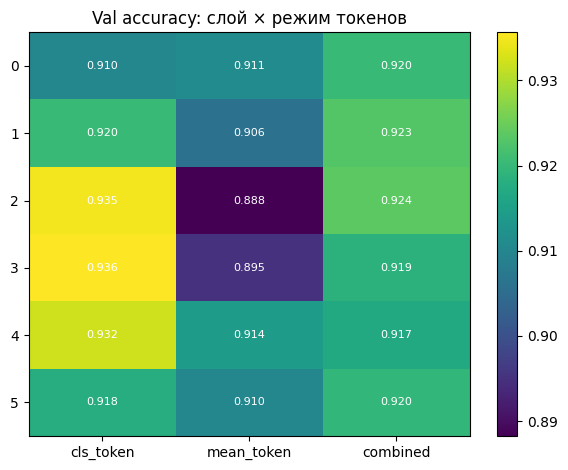

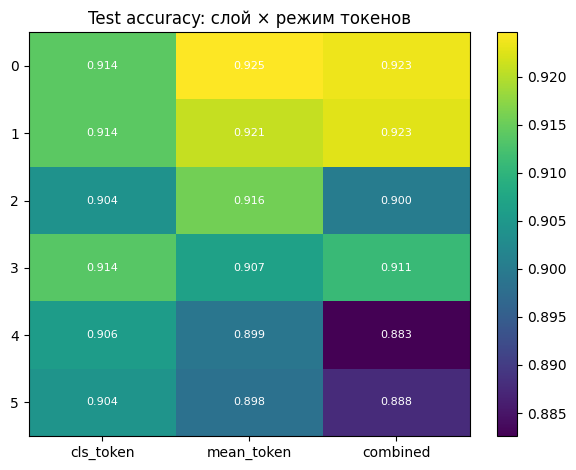

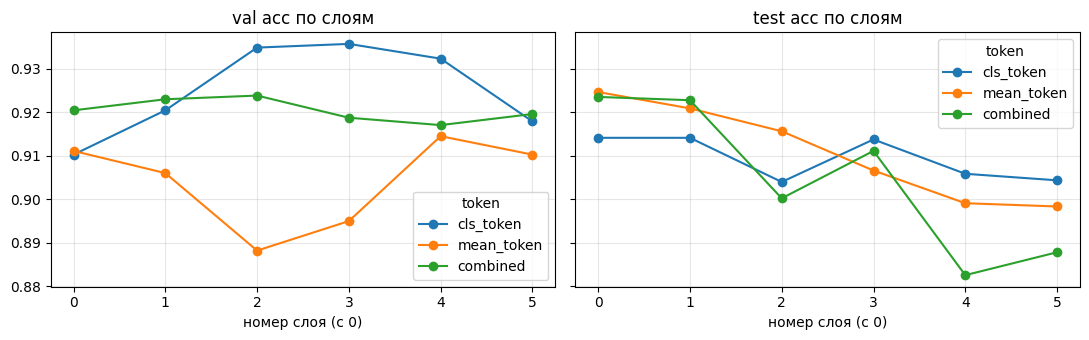


Лучшая по val конфигурация: layer=3, token=cls_token (val 0.9356, test acc 0.9137, F1 0.9132)

Лучший слой для каждого режима токенов (по val):


token,cls_token,mean_token,combined
best_layer,3,4,2


Выигрыш combined относительно cls_token на лучших слоях (val): -0.0119


In [ ]:
def heatmap(df, title, fmt=".3f"):
    fig, ax = plt.subplots(figsize=(1.0 * df.shape[1] + 3, 0.55 * df.shape[0] + 1.5))
    im = ax.imshow(df.values.astype(float), aspect="auto", cmap="viridis")
    ax.set_xticks(range(df.shape[1])); ax.set_xticklabels(df.columns)
    ax.set_yticks(range(df.shape[0])); ax.set_yticklabels(df.index)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            ax.text(j, i, format(float(df.values[i, j]), fmt), ha="center", va="center", color="w", fontsize=8)
    ax.set_title(title); plt.colorbar(im); plt.tight_layout(); plt.show()


grid_rows = []
for tok in TOKENS:
    for layer in range(cfg.n_layers):
        t0 = time.time()
        Z = get_features(layer, tok)
        r = eval_clf(make_lr(), Z, cap=cfg.grid_train_cap)
        grid_rows.append(dict(layer=layer, token=tok, **r))
        print(f"layer {layer} | {tok:10s} | dim {Z['train'].shape[1]:5d} | val {r['val_acc']:.4f} | "
              f"test {r['test_acc']:.4f} | {time.time()-t0:.0f} c")

grid_df = pd.DataFrame(grid_rows)
grid_df.to_csv(cfg.workdir / "grid_layers_tokens.csv", index=False)

val_tab = grid_df.pivot(index="layer", columns="token", values="val_acc")[TOKENS]
test_tab = grid_df.pivot(index="layer", columns="token", values="test_acc")[TOKENS]
heatmap(val_tab, "Val accuracy: слой × режим токенов")
heatmap(test_tab, "Test accuracy: слой × режим токенов")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
val_tab.plot(marker="o", ax=ax[0], title="val acc по слоям"); test_tab.plot(marker="o", ax=ax[1], title="test acc по слоям")
for a in ax: a.set_xlabel("номер слоя (с 0)"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

best = grid_df.sort_values("val_acc").iloc[-1]
BEST_LAYER, BEST_TOKEN = int(best["layer"]), best["token"]
print(f"\nЛучшая по val конфигурация: layer={BEST_LAYER}, token={BEST_TOKEN} "
      f"(val {best['val_acc']:.4f}, test acc {best['test_acc']:.4f}, F1 {best['test_f1']:.4f})")
add_result(f"Mantis frozen best-by-val L{BEST_LAYER}/{BEST_TOKEN} + LogReg", best["val_acc"], best["test_acc"], best["test_f1"])

print("\nЛучший слой для каждого режима токенов (по val):")
display(val_tab.idxmax().rename("best_layer").to_frame().T)
print("Выигрыш combined относительно cls_token на лучших слоях (val):",
      f"{val_tab['combined'].max() - val_tab['cls_token'].max():+.4f}")

## 6. Абляция: один масштаб vs объединение нескольких масштабов
Идея Self-Ensembling (SE) из статьи: при фиксированных 32 токенах длина интерполяции меняет размер/перекрытие рецептивного поля токена, поэтому признаки одного и того же ряда на разных масштабах комплементарны. Сравниваем признаки каждого масштаба по отдельности с конкатенацией нескольких (слой и режим токенов берутся лучшие из раздела 5).
Размерность конкатенации растёт линейно; при нехватке памяти уменьшите `cfg.scales`, `channels_mode` или используйте `cls_token`.

single_128             | dim   4608 | val 0.9077 | test 0.9160 | F1 0.9146
single_256             | dim   4608 | val 0.9255 | test 0.9104 | F1 0.9087
single_512             | dim   4608 | val 0.9356 | test 0.9137 | F1 0.9132
single_1024            | dim   4608 | val 0.9306 | test 0.9111 | F1 0.9153
concat_all             | dim  18432 | val 0.9348 | test 0.9122 | F1 0.9132
concat_256_512_1024    | dim  13824 | val 0.9373 | test 0.9051 | F1 0.9063
concat_512_1024        | dim   9216 | val 0.9246 | test 0.9051 | F1 0.9069


,config,dim,val_acc,test_acc,test_f1,fit_time
0,single_128,4608,0.907705,0.915979,0.914586,4.756527
1,single_256,4608,0.925487,0.910353,0.908733,5.657439
2,single_512,4608,0.935648,0.913728,0.913186,5.058249
3,single_1024,4608,0.930567,0.911103,0.915254,4.977348
4,concat_all,18432,0.934801,0.912228,0.913155,16.869069
5,concat_256_512_1024,13824,0.937341,0.905101,0.906294,11.539546
6,concat_512_1024,9216,0.924640,0.905101,0.906866,7.860824


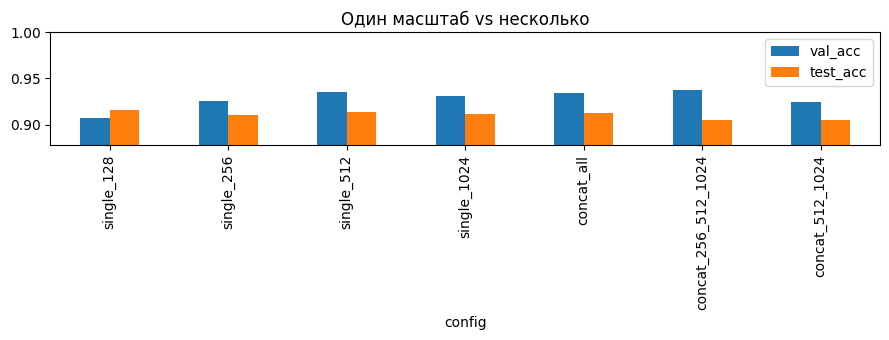

Лучшая по val конфигурация масштабов: concat_256_512_1024 (scales=(256, 512, 1024))


In [ ]:
scale_feats = {s: get_features(BEST_LAYER, BEST_TOKEN, s) for s in cfg.scales}

combos = {f"single_{s}": [s] for s in cfg.scales}
combos["concat_all"] = list(cfg.scales)
if {256, 512, 1024} <= set(cfg.scales):
    combos["concat_256_512_1024"] = [256, 512, 1024]
if {512, 1024} <= set(cfg.scales):
    combos["concat_512_1024"] = [512, 1024]

ms_rows = []
for name, sc in combos.items():
    Z = {sp: np.concatenate([scale_feats[s][sp] for s in sc], axis=1) for sp in SPLITS_X}
    r = eval_clf(make_lr(), Z)
    ms_rows.append(dict(config=name, scales=sc, dim=Z["train"].shape[1], **r))
    print(f"{name:22s} | dim {Z['train'].shape[1]:6d} | val {r['val_acc']:.4f} | test {r['test_acc']:.4f} | F1 {r['test_f1']:.4f}")

ms_df = pd.DataFrame(ms_rows)
ms_df.to_csv(cfg.workdir / "ablation_scales.csv", index=False)
display(ms_df[["config", "dim", "val_acc", "test_acc", "test_f1", "fit_time"]])
ms_df.set_index("config")[["val_acc", "test_acc"]].plot.bar(figsize=(9, 3.5), ylim=(ms_df.val_acc.min() - .03, 1.0),
                                                           title="Один масштаб vs несколько")
plt.tight_layout(); plt.show()

bm = ms_df.sort_values("val_acc").iloc[-1]
BEST_SCALES = tuple(bm["scales"])
print(f"Лучшая по val конфигурация масштабов: {bm['config']} (scales={BEST_SCALES})")
add_result(f"Mantis frozen L{BEST_LAYER}/{BEST_TOKEN} scales={BEST_SCALES} + LogReg", bm["val_acc"], bm["test_acc"], bm["test_f1"])

## 7. Разные классификаторы поверх признаков Mantis: LogReg, Linear SVM, RBF-SVM, Ridge, RandomForest, бустинги
Признаки: лучшие из разделов 5–6 (`FEAT_CFG` можно поменять вручную). Для каждой модели небольшой перебор гиперпараметра **по val**; для деревьев/бустингов перед моделью ставится StandardScaler + PCA (`cfg.pca_dim_for_trees`) — иначе на тысячах признаков они очень медленные.

FEAT_CFG: {'layer': 3, 'token': 'cls_token', 'scales': (256, 512, 1024)} | dim: 13824
  LogReg       param=0.01     val 0.9458 | test 0.9231 | 15 c
  LogReg       param=0.1      val 0.9424 | test 0.9141 | 11 c
  LogReg       param=1.0      val 0.9373 | test 0.9051 | 12 c
  LinearSVM    param=0.0001   val 0.9467 | test 0.9066 | 86 c
  LinearSVM    param=0.001    val 0.9416 | test 0.9044 | 278 c
  LinearSVM    param=0.01     val 0.9407 | test 0.9025 | 656 c
  SVM-RBF      param=1.0      val 0.9475 | test 0.9291 | 389 c
  SVM-RBF      param=10.0     val 0.9534 | test 0.9302 | 400 c
  Ridge        param=100.0    val 0.9594 | test 0.9197 | 9 c
  Ridge        param=1000.0   val 0.9610 | test 0.9224 | 9 c
  Ridge        param=10000.0  val 0.9585 | test 0.9295 | 9 c
  RandomForest param=300      val 0.9246 | test 0.9014 | 28 c
  HistGB       param=0.05     val 0.9272 | test 0.9066 | 24 c
  HistGB       param=0.1      val 0.9297 | test 0.9085 | 18 c
  LightGBM     param=0.03     val 0.9433 | te

,classifier,best_param,val_acc,test_acc,test_f1,fit_time
3,Ridge,1000.0000,0.961050,0.922356,0.926084,8.785607
2,SVM-RBF,10.0000,0.953429,0.930233,0.928278,400.034356
1,LinearSVM,0.0001,0.946655,0.906602,0.908397,85.518787
0,LogReg,0.0100,0.945809,0.923106,0.923986,15.208351
6,LightGBM,0.1000,0.944962,0.925731,0.924410,28.027129
5,HistGB,0.1000,0.929721,0.908477,0.908116,17.959785
4,RandomForest,300.0000,0.924640,0.901350,0.903616,27.518047


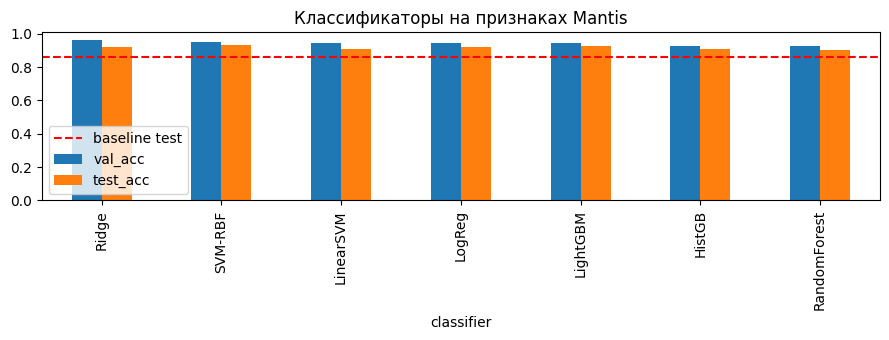

In [ ]:
from sklearn.decomposition import PCA
from sklearn.svm import LinearSVC, SVC
from sklearn.linear_model import RidgeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None

FEAT_CFG = dict(layer=BEST_LAYER, token=BEST_TOKEN, scales=BEST_SCALES)   # при желании измените вручную
Zc = get_multiscale_features(FEAT_CFG["layer"], FEAT_CFG["token"], FEAT_CFG["scales"])
print("FEAT_CFG:", FEAT_CFG, "| dim:", Zc["train"].shape[1])

def pca():
    return PCA(n_components=cfg.pca_dim_for_trees, random_state=cfg.seed)

CANDIDATES = {
    "LogReg":       (lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=500)), [0.01, 0.1, 1.0]),
    "LinearSVM":    (lambda C: make_pipeline(StandardScaler(), LinearSVC(C=C, max_iter=5000)), [1e-4, 1e-3, 1e-2]),
    "SVM-RBF":      (lambda C: make_pipeline(StandardScaler(), SVC(C=C, kernel="rbf", gamma="scale")), [1.0, 10.0]),
    "Ridge":        (lambda a: make_pipeline(StandardScaler(), RidgeClassifier(alpha=a)), [100.0, 1000.0, 10000.0]),
    "RandomForest": (lambda n: make_pipeline(StandardScaler(), pca(),
                     RandomForestClassifier(n_estimators=n, n_jobs=-1, random_state=cfg.seed)), [300]),
    "HistGB":       (lambda lr: make_pipeline(StandardScaler(), pca(),
                     HistGradientBoostingClassifier(learning_rate=lr, max_iter=300, early_stopping=True,
                                                    random_state=cfg.seed)), [0.05, 0.1]),
}
if LGBMClassifier is not None:
    CANDIDATES["LightGBM"] = (lambda lr: make_pipeline(StandardScaler(), pca(),
        LGBMClassifier(n_estimators=500, learning_rate=lr, num_leaves=31, subsample=0.8, subsample_freq=1,
                       colsample_bytree=0.8, random_state=cfg.seed, n_jobs=-1, verbose=-1)), [0.03, 0.1])

clf_rows = []
for name, (mk, grid) in CANDIDATES.items():
    best_r, best_p = None, None
    for p in grid:
        r = eval_clf(mk(p), Zc)
        print(f"  {name:12s} param={p:<8} val {r['val_acc']:.4f} | test {r['test_acc']:.4f} | {r['fit_time']:.0f} c")
        if best_r is None or r["val_acc"] > best_r["val_acc"]:
            best_r, best_p = r, p
    clf_rows.append(dict(classifier=name, best_param=best_p, **best_r))
    add_result(f"Mantis feats ({FEAT_CFG['layer']}/{FEAT_CFG['token']}/{FEAT_CFG['scales']}) + {name}",
               best_r["val_acc"], best_r["test_acc"], best_r["test_f1"])

clf_df = pd.DataFrame(clf_rows).sort_values("val_acc", ascending=False)
clf_df.to_csv(cfg.workdir / "classifiers.csv", index=False)
display(clf_df)
clf_df.set_index("classifier")[["val_acc", "test_acc"]].plot.bar(figsize=(9, 3.5), title="Классификаторы на признаках Mantis")
plt.axhline(bl["test_acc"], color="r", ls="--", label="baseline test"); plt.legend(); plt.tight_layout(); plt.show()

## 8. Как число эпох влияет на то, какой слой лучше
Дообучаем весь кодировщик Mantis (последний слой + `BatchNorm+Linear` голова, `lr=2e-4`, `AdamW`, как в статье) на подвыборке train PAMAP2. На контрольных эпохах `cfg.ft_checkpoints` сохраняем веса кодировщика, затем **замораживаем** их, снова извлекаем признаки из каждого слоя `0..n_layers-1` и обучаем линейный пробинг. Эпоха 0 — исходный предобученный Mantis.
Гипотеза из статьи: чем дольше обучается сеть, тем сильнее последний слой «подстраивается» под свою задачу, и лучший слой смещается ближе к началу/середине.

fine-tune epoch   1 | train loss 0.3517 | val acc (end-to-end) 0.9179
fine-tune epoch   2 | train loss 0.1083 | val acc (end-to-end) 0.9543
fine-tune epoch   3 | train loss 0.0496 | val acc (end-to-end) 0.9568
fine-tune epoch   4 | train loss 0.0201 | val acc (end-to-end) 0.9467
fine-tune epoch   5 | train loss 0.0094 | val acc (end-to-end) 0.9306
fine-tune epoch   6 | train loss 0.0047 | val acc (end-to-end) 0.9517
fine-tune epoch   7 | train loss 0.0030 | val acc (end-to-end) 0.9517
fine-tune epoch   8 | train loss 0.0023 | val acc (end-to-end) 0.9534
fine-tune epoch   9 | train loss 0.0017 | val acc (end-to-end) 0.9543
fine-tune epoch  10 | train loss 0.0016 | val acc (end-to-end) 0.9526
fine-tune epoch  11 | train loss 0.0015 | val acc (end-to-end) 0.9526
fine-tune epoch  12 | train loss 0.0010 | val acc (end-to-end) 0.9500
fine-tune epoch  13 | train loss 0.0009 | val acc (end-to-end) 0.9526
fine-tune epoch  14 | train loss 0.0008 | val acc (end-to-end) 0.9500
fine-tune epoch  15 

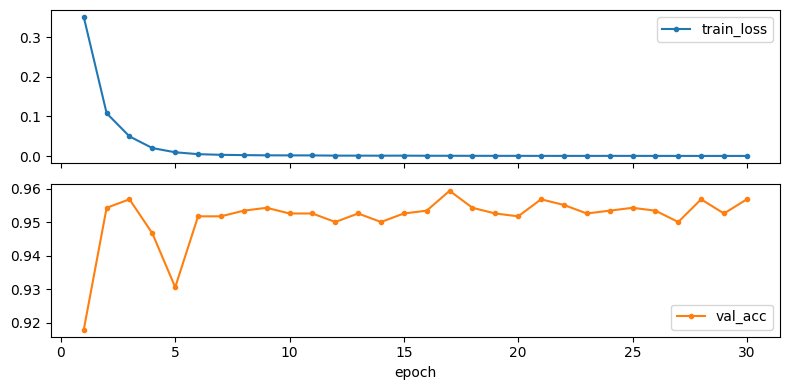

In [ ]:
class FineTuneModel(nn.Module):
    def __init__(self, encoder, n_channels, n_classes):
        super().__init__()
        self.encoder = encoder
        with torch.no_grad():
            encoder.eval()
            q = encoder(torch.zeros(2, 1, cfg.mantis_len, device=cfg.device)).shape[-1]
        self.head = nn.Sequential(nn.BatchNorm1d(n_channels * q), nn.Linear(n_channels * q, n_classes))

    def forward(self, x):                              # x: (B, C, L) -> каналы независимо через энкодер
        B, C, L = x.shape
        z = self.encoder(x.reshape(B * C, 1, L))
        return self.head(z.reshape(B, -1))


rng = np.random.RandomState(cfg.seed)
ft_idx = rng.choice(len(X_train), min(cfg.ft_train_cap, len(X_train)), replace=False)
Xft = torch.from_numpy(resize_to(X_train[ft_idx], cfg.mantis_len))
yft = torch.from_numpy(y_train[ft_idx])
Xva_ft = resize_to(X_val, cfg.mantis_len)

set_seed()
ft_model = FineTuneModel(build_network(), N_CH, N_CLASSES).to(cfg.device)
opt = torch.optim.AdamW(ft_model.parameters(), lr=cfg.ft_lr, weight_decay=cfg.ft_weight_decay)

ckpts = sorted(set(cfg.ft_checkpoints))
ckpt_states = {}
def snapshot(ep):
    ckpt_states[ep] = {k: v.detach().cpu().clone() for k, v in ft_model.encoder.state_dict().items()}
if 0 in ckpts:
    snapshot(0)

@torch.no_grad()
def ft_val_acc():
    ft_model.eval()
    preds = []
    for i in range(0, len(Xva_ft), 64):
        preds.append(ft_model(torch.from_numpy(Xva_ft[i:i + 64]).to(cfg.device)).argmax(1).cpu().numpy())
    return accuracy_score(y_val, np.concatenate(preds))

ft_log = []
for ep in range(1, max(ckpts) + 1):
    ft_model.train()
    perm = torch.randperm(len(Xft))
    tot, n = 0.0, 0
    for i in range(0, len(perm), cfg.ft_batch):
        idx = perm[i:i + cfg.ft_batch]
        if len(idx) < 2:
            continue
        xb, yb = Xft[idx].to(cfg.device), yft[idx].to(cfg.device)
        loss = F.cross_entropy(ft_model(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(idx); n += len(idx)
    va = ft_val_acc()
    ft_log.append((ep, tot / n, va))
    print(f"fine-tune epoch {ep:3d} | train loss {tot/n:.4f} | val acc (end-to-end) {va:.4f}")
    if ep in ckpts:
        snapshot(ep)

ft_log_df = pd.DataFrame(ft_log, columns=["epoch", "train_loss", "val_acc"])
ft_log_df.plot(x="epoch", y=["train_loss", "val_acc"], subplots=True, figsize=(8, 4), marker=".")
plt.tight_layout(); plt.show()

load_state_dict: missing=0, unexpected=0
эпоха   0: лучший слой = 3 (val 0.9255) | 139 c
эпоха   1: лучший слой = 1 (val 0.9196) | 138 c
эпоха   2: лучший слой = 5 (val 0.9340) | 135 c
эпоха   5: лучший слой = 5 (val 0.9543) | 132 c
эпоха  10: лучший слой = 5 (val 0.9500) | 132 c
эпоха  20: лучший слой = 5 (val 0.9526) | 131 c
эпоха  30: лучший слой = 5 (val 0.9551) | 133 c


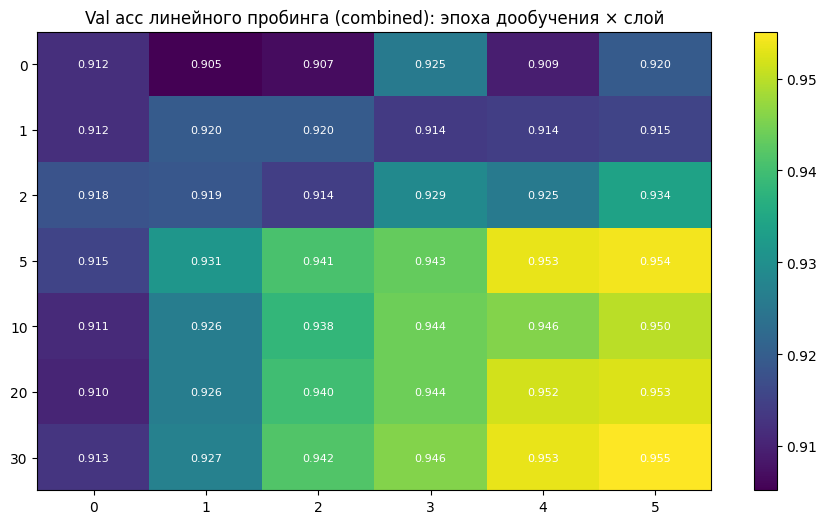

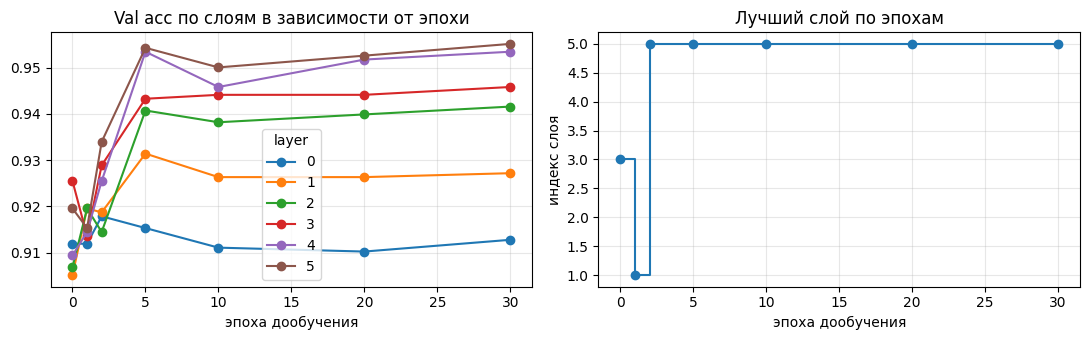

epoch,0,1,2,5,10,20,30
best_layer,3,1,5,5,5,5,5


In [ ]:
probe_idx = np.random.RandomState(cfg.seed + 1).choice(len(X_train), min(cfg.ft_probe_train_cap, len(X_train)), replace=False)
Xp_tr, yp_tr = X_train[probe_idx], y_train[probe_idx]
_printed = {"done": False}

def probe_layers_for_state(state):
    row = {}
    for layer in range(cfg.n_layers):
        net = build_network(layer, cfg.ft_probe_token)
        res = net.load_state_dict(state, strict=False)       # подставляем веса дообученного кодировщика
        if not _printed["done"]:
            print(f"load_state_dict: missing={len(res.missing_keys)}, unexpected={len(res.unexpected_keys)}")
            _printed["done"] = True
        trainer = MantisTrainer(device=cfg.device, network=net)
        Ztr = transform_chunks(trainer, Xp_tr, cfg.mantis_len)
        Zva = transform_chunks(trainer, X_val, cfg.mantis_len)
        clf = make_lr().fit(Ztr, yp_tr)
        row[layer] = accuracy_score(y_val, clf.predict(Zva))
    return row

epoch_rows = {}
for ep in ckpts:
    t0 = time.time()
    epoch_rows[ep] = probe_layers_for_state(ckpt_states[ep])
    br = max(epoch_rows[ep], key=epoch_rows[ep].get)
    print(f"эпоха {ep:3d}: лучший слой = {br} (val {epoch_rows[ep][br]:.4f}) | {time.time()-t0:.0f} c")

epoch_layer_df = pd.DataFrame(epoch_rows).T
epoch_layer_df.index.name = "epoch"; epoch_layer_df.columns.name = "layer"
epoch_layer_df.to_csv(cfg.workdir / "epochs_vs_layers.csv")
heatmap(epoch_layer_df, f"Val acc линейного пробинга ({cfg.ft_probe_token}): эпоха дообучения × слой")

best_layer_by_epoch = epoch_layer_df.idxmax(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
epoch_layer_df.plot(marker="o", ax=ax[0], title="Val acc по слоям в зависимости от эпохи")
ax[0].set_xlabel("эпоха дообучения"); ax[0].grid(alpha=.3)
ax[1].step(best_layer_by_epoch.index, best_layer_by_epoch.values, where="post", marker="o")
ax[1].set_title("Лучший слой по эпохам"); ax[1].set_xlabel("эпоха дообучения"); ax[1].set_ylabel("индекс слоя"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
display(best_layer_by_epoch.rename("best_layer").to_frame().T)

## 9. Когда Mantis реально помогает: кривая обучения + итоги
Сравниваем бейзлайн-трансформер (с нуля) и замороженный Mantis + LogReg при разном объёме размеченного train (стратифицированная подвыборка окон). Val/test те же. Для надёжных выводов повторите с несколькими `seed` (здесь один запуск).

frac  0.02 (n=  121) | Mantis test 0.8421 | baseline test 0.6842 | Δ=+0.1579
frac  0.05 (n=  302) | Mantis test 0.8650 | baseline test 0.7783 | Δ=+0.0866
frac  0.10 (n=  605) | Mantis test 0.8987 | baseline test 0.8237 | Δ=+0.0750
frac  0.25 (n= 1514) | Mantis test 0.9212 | baseline test 0.8496 | Δ=+0.0716
frac  1.00 (n= 6058) | Mantis test 0.9051 | baseline test 0.8616 | Δ=+0.0435


,fraction,n_train,mantis_test,mantis_f1,baseline_test,baseline_f1,delta_acc
0,0.02,121,0.842086,0.852497,0.684171,0.641224,0.157914
1,0.05,302,0.864966,0.867543,0.778320,0.719767,0.086647
2,0.10,605,0.898725,0.899211,0.823706,0.794687,0.075019
3,0.25,1514,0.921230,0.923151,0.849587,0.843092,0.071643
4,1.00,6058,0.905101,0.906294,0.861590,0.854217,0.043511


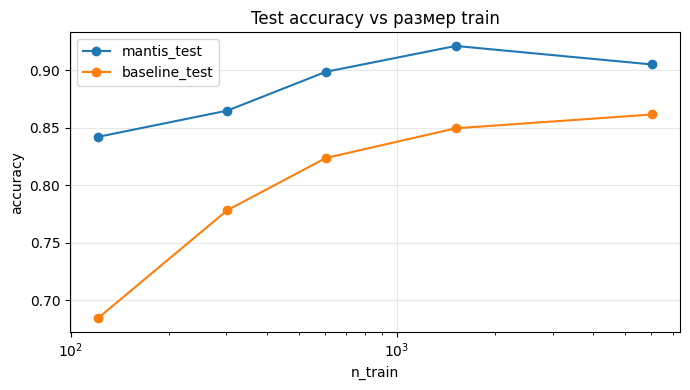

In [ ]:
from sklearn.model_selection import train_test_split

Z_lc = get_multiscale_features(FEAT_CFG["layer"], FEAT_CFG["token"], FEAT_CFG["scales"])
lc_rows = []
for frac in cfg.lc_fractions:
    if frac < 1.0:
        idx, _ = train_test_split(np.arange(len(y_train)), train_size=frac, stratify=y_train, random_state=cfg.seed)
    else:
        idx = np.arange(len(y_train))
    # Mantis frozen + LogReg
    clf = make_lr().fit(Z_lc["train"][idx], y_train[idx])
    m_va = accuracy_score(y_val, clf.predict(Z_lc["val"]))
    m_te, m_f1 = metrics(y_test, clf.predict(Z_lc["test"]))
    # baseline transformer
    b = train_baseline(X_train[idx], y_train[idx], X_val, y_val, X_test, y_test, verbose=False)
    lc_rows.append(dict(fraction=frac, n_train=len(idx), mantis_test=m_te, mantis_f1=m_f1,
                        baseline_test=b["test_acc"], baseline_f1=b["test_f1"]))
    print(f"frac {frac:5.2f} (n={len(idx):5d}) | Mantis test {m_te:.4f} | baseline test {b['test_acc']:.4f} | "
          f"Δ={m_te-b['test_acc']:+.4f}")

lc_df = pd.DataFrame(lc_rows)
lc_df["delta_acc"] = lc_df["mantis_test"] - lc_df["baseline_test"]
lc_df.to_csv(cfg.workdir / "learning_curve.csv", index=False)
display(lc_df)
ax = lc_df.plot(x="n_train", y=["mantis_test", "baseline_test"], marker="o", logx=True, figsize=(7, 4),
                title="Test accuracy vs размер train")
ax.set_ylabel("accuracy"); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

In [ ]:
res_df = pd.DataFrame(RESULTS).sort_values("test_acc", ascending=False).reset_index(drop=True)
res_df.to_csv(cfg.workdir / "all_results.csv", index=False)
pd.set_option("display.max_colwidth", 90)
display(res_df[["model", "val_acc", "test_acc", "test_f1"]])

bl_row = res_df[res_df.model.str.startswith("Baseline")].iloc[0]
mantis_best = res_df[res_df.model.str.startswith("Mantis")].iloc[0]
print(f"Baseline: test acc {bl_row.test_acc:.4f} | F1 {bl_row.test_f1:.4f}")
print(f"Лучший Mantis (по test, только для справки): {mantis_best.model}\n"
      f"  test acc {mantis_best.test_acc:.4f} | F1 {mantis_best.test_f1:.4f} | Δacc к baseline {mantis_best.test_acc-bl_row.test_acc:+.4f}")
print("\nГде Mantis выигрывает по объёму данных (Δacc > 0):")
print(lc_df.loc[lc_df.delta_acc > 0, ["n_train", "delta_acc"]].to_string(index=False) or "нигде")

,model,val_acc,test_acc,test_f1
0,"Mantis feats (3/cls_token/(256, 512, 1024)) + SVM-RBF",0.953429,0.930233,0.928278
1,"Mantis feats (3/cls_token/(256, 512, 1024)) + LightGBM",0.944962,0.925731,0.924410
2,"Mantis feats (3/cls_token/(256, 512, 1024)) + LogReg",0.945809,0.923106,0.923986
3,"Mantis feats (3/cls_token/(256, 512, 1024)) + Ridge",0.961050,0.922356,0.926084
4,Mantis frozen best-by-val L3/cls_token + LogReg,0.935648,0.913728,0.913186
5,"Mantis feats (3/cls_token/(256, 512, 1024)) + HistGB",0.929721,0.908477,0.908116
6,"Mantis feats (3/cls_token/(256, 512, 1024)) + LinearSVM",0.946655,0.906602,0.908397
7,"Mantis frozen L3/cls_token scales=(256, 512, 1024) + LogReg",0.937341,0.905101,0.906294
8,Mantis frozen L5/cls_token + LogReg,0.917866,0.904351,0.906992
9,"Mantis feats (3/cls_token/(256, 512, 1024)) + RandomForest",0.924640,0.901350,0.903616


Baseline: test acc 0.8593 | F1 0.8602
Лучший Mantis (по test, только для справки): Mantis feats (3/cls_token/(256, 512, 1024)) + SVM-RBF
  test acc 0.9302 | F1 0.9283 | Δacc к baseline +0.0709

Где Mantis выигрывает по объёму данных (Δacc > 0):
 n_train  delta_acc
     121   0.157914
     302   0.086647
     605   0.075019
    1514   0.071643
    6058   0.043511


## 10. Выводы

1. Мантис по сравнению с обычным трансформером отработал намного лучше, лучший Мантис показал 0.9302 скор на тесте а у обычного трансформера 0.8593
2. Сравнение CLS, mean, combined токенов будем проводить по результатам на тесте: чем выше слой тем хуже получались результаты у каждого из токенов, но лучшие результаты получались у комбинированного токена, хотя более стабильный по всем слоям был CLS
3. Изменение масштабов не дало большого изменения в метриках
4. Сравнение слоёв на разных эпохах: на маленьких эпохах все слои выдают примерно одинаковые результаты но чем больше слоев тем лучше себя показывают последние слои(5-6)

итоги: на данных PAMAP2 мантис даёт хороший прирост к метрикам по сравнению с обычным трансформером за счет контрастивного предобучения на искусственных рядах, TokenGeneration Unit-a и выбора лучшего слоя трансформера(не обязательно последнего)